<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Sector_and_industry_cluster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['TATAMOTORS.NS']: YFTzMissingError('possibly delisted; no timezone found')


K-MEANS SECTOR & INDUSTRY CLUSTERING
Stocks available : 29
Observations     : 2,154

Feature matrix:
(29, 10)

K SELECTION
---------------------------------------------------------------------------


,K,Inertia,Silhouette_Score
0,2,217.40,0.4035
1,3,179.51,0.1725
2,4,148.71,0.1407
3,5,121.36,0.1500
4,6,105.44,0.1629
5,7,90.73,0.1831
6,8,78.75,0.1723



Optimal K                 : 2
Best Silhouette Score    : 0.4035


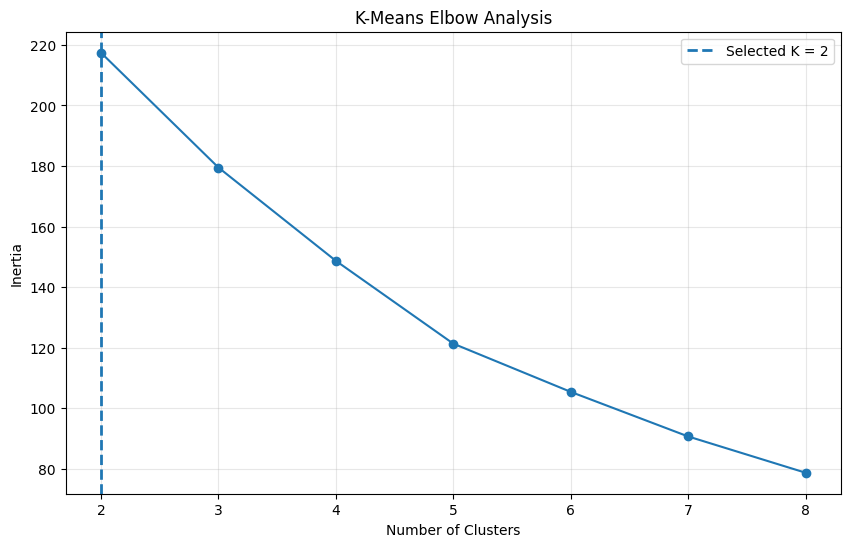

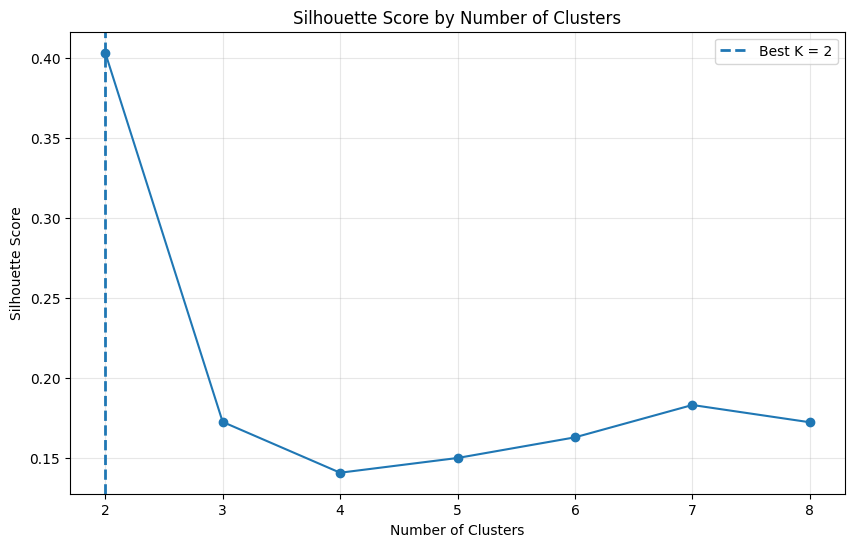


CLUSTER PROFILES
---------------------------------------------------------------------------


,Annual_Return,Annual_Volatility,Sharpe_Ratio,Downside_Volatility,Max_Drawdown,Skewness,Excess_Kurtosis,NIFTY_Correlation,Momentum_20D,Momentum_60D,Number_of_Stocks
Cluster,,,,,,,,,,,
0,0.1241,0.2824,0.436,0.2038,-0.5051,-0.2005,7.2107,0.5550,-0.0323,-0.0151,26
1,0.2370,0.3993,0.556,0.3245,-0.6563,-1.0748,21.8128,0.6192,-0.0291,-0.0434,3



STOCKS WITHIN EACH CLUSTER
---------------------------------------------------------------------------

Cluster 0 (26 stocks)
BHARTIARTL, COALINDIA, EICHERMOT, HCLTECH, HDFCBANK, HINDUNILVR, ICICIBANK, INFY, ITC, JSWSTEEL, KOTAKBANK, LT, M&M, MARUTI, NTPC, ONGC, POWERGRID, RELIANCE, SBIN, SUNPHARMA, TATASTEEL, TCS, TECHM, TITAN, ULTRACEMCO, WIPRO

Cluster 1 (3 stocks)
ADANIENT, AXISBANK, BAJFINANCE

CLUSTER × SECTOR MATRIX
---------------------------------------------------------------------------


Sector,Automobiles,Construction,Consumer Discretionary,Consumer Staples,Energy,Financials,Healthcare,Industrials,Information Technology,Metals,Telecommunication,Utilities
Cluster,,,,,,,,,,,,
0,3,2,1,2,3,4,1,0,5,2,1,2
1,0,0,0,0,0,2,0,1,0,0,0,0



SECTOR COMPOSITION (%)


Sector,Automobiles,Construction,Consumer Discretionary,Consumer Staples,Energy,Financials,Healthcare,Industrials,Information Technology,Metals,Telecommunication,Utilities
Cluster,,,,,,,,,,,,
0,11.54,7.69,3.85,7.69,11.54,15.38,3.85,0.00,19.23,7.69,3.85,7.69
1,0.00,0.00,0.00,0.00,0.00,66.67,0.00,33.33,0.00,0.00,0.00,0.00



CLUSTER SECTOR PURITY


,Dominant_Sector,Purity_%
Cluster,,
0,Information Technology,19.23%
1,Financials,66.67%


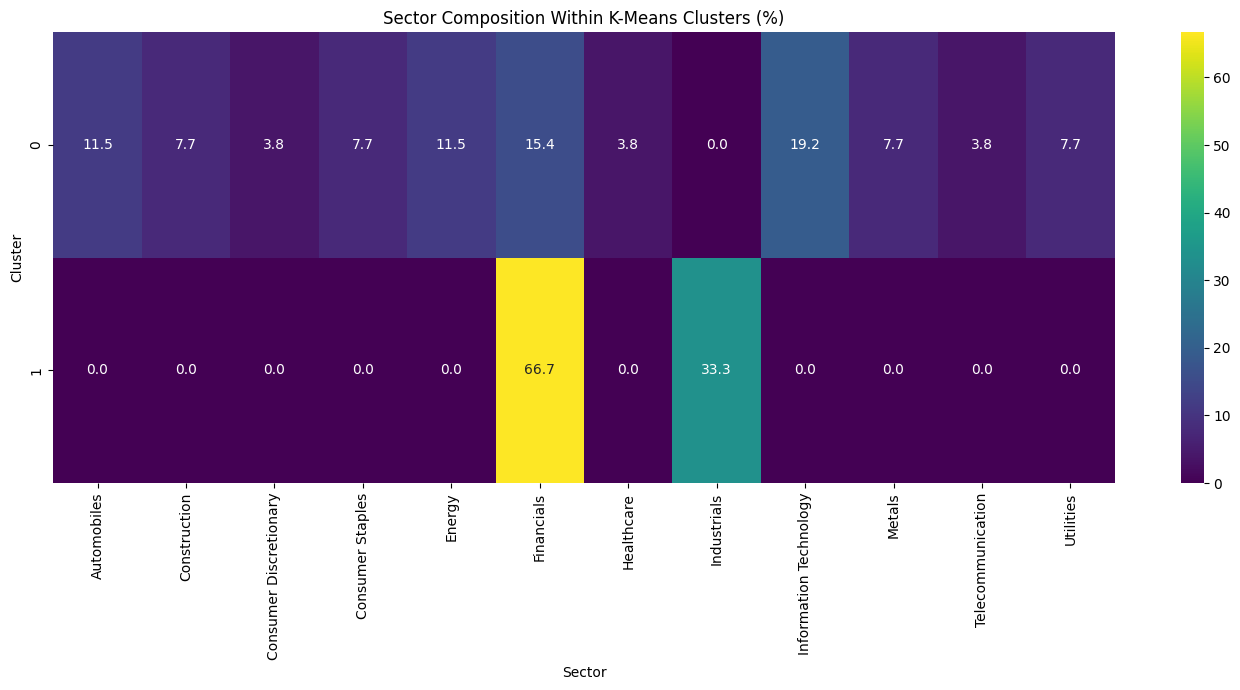

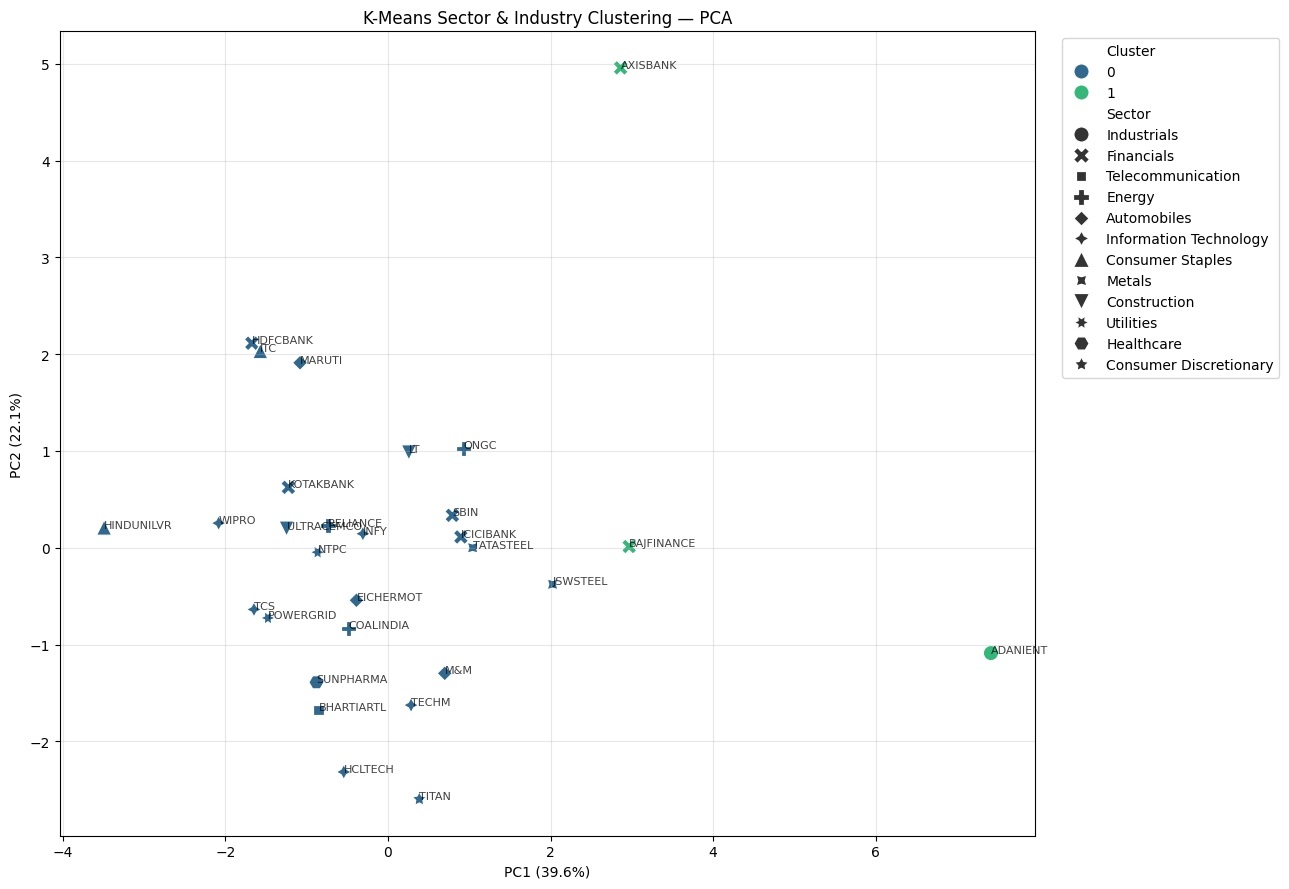


STOCK-LEVEL CLUSTER ASSIGNMENTS


,Sector,Cluster,Annual_Return,Annual_Volatility,Sharpe_Ratio,Downside_Volatility,Max_Drawdown,Skewness,Excess_Kurtosis,NIFTY_Correlation,Momentum_20D,Momentum_60D
Stock,,,,,,,,,,,,
EICHERMOT.NS,Automobiles,0,0.1167,0.3086,0.3780,0.2129,-0.5909,0.0389,3.9942,0.5528,-0.0614,0.0009
M&M.NS,Automobiles,0,0.1755,0.3156,0.5562,0.2160,-0.7228,0.2239,4.8477,0.6099,-0.1010,0.0123
MARUTI.NS,Automobiles,0,0.0369,0.2823,0.1308,0.2072,-0.5826,-0.1484,11.2902,0.6143,-0.1113,-0.0724
LT.NS,Construction,0,0.1445,0.2694,0.5361,0.1983,-0.5444,-0.5582,10.4729,0.6957,-0.0578,-0.0894
ULTRACEMCO.NS,Construction,0,0.1144,0.2666,0.4291,0.1866,-0.3750,-0.1522,7.0913,0.6476,-0.0655,-0.0448
TITAN.NS,Consumer Discretionary,0,0.2085,0.2780,0.7501,0.2073,-0.4173,-0.2917,7.0266,0.5478,-0.0315,0.1390
HINDUNILVR.NS,Consumer Staples,0,0.0602,0.2239,0.2691,0.1480,-0.3378,0.5865,8.3540,0.4407,-0.0290,-0.0907
ITC.NS,Consumer Staples,0,0.0457,0.2360,0.1935,0.1767,-0.5305,-0.6281,10.8275,0.4992,-0.0109,-0.0902
COALINDIA.NS,Energy,0,0.1396,0.2964,0.4712,0.2018,-0.5708,-0.0207,3.8428,0.4289,0.0690,-0.0191



FINAL MODEL VALIDATION
---------------------------------------------------------------------------
Optimal K              : 2
Silhouette Score       : 0.4035
PC1 + PC2 Variance     : 61.64%

Files saved:
• KMeans_Sector_Industry_Clusters.csv
• KMeans_Sector_Cluster_Profiles.csv
• KMeans_Cluster_Sector_Matrix.csv
• KMeans_Sector_Composition.csv
• KMeans_Sector_Purity.csv
• KMeans_Silhouette_Evaluation.csv
• KMeans_PCA_Sector_Projection.csv

PROJECT 3 COMPLETED


In [ ]:
# ============================================================
# K-MEANS SECTOR & INDUSTRY CLUSTERING
# NIFTY 50 STOCKS | SILHOUETTE + K-MEANS + SECTOR ANALYSIS
# ============================================================

!pip -q install yfinance scikit-learn scipy matplotlib seaborn pandas numpy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 1. STOCK UNIVERSE + SECTOR INFORMATION
# ------------------------------------------------------------

stocks = {
    "RELIANCE.NS": "Energy",
    "ONGC.NS": "Energy",
    "COALINDIA.NS": "Energy",
    "NTPC.NS": "Utilities",
    "POWERGRID.NS": "Utilities",
    "HDFCBANK.NS": "Financials",
    "ICICIBANK.NS": "Financials",
    "SBIN.NS": "Financials",
    "AXISBANK.NS": "Financials",
    "KOTAKBANK.NS": "Financials",
    "BAJFINANCE.NS": "Financials",
    "INFY.NS": "Information Technology",
    "TCS.NS": "Information Technology",
    "HCLTECH.NS": "Information Technology",
    "WIPRO.NS": "Information Technology",
    "TECHM.NS": "Information Technology",
    "BHARTIARTL.NS": "Telecommunication",
    "ITC.NS": "Consumer Staples",
    "HINDUNILVR.NS": "Consumer Staples",
    "TITAN.NS": "Consumer Discretionary",
    "MARUTI.NS": "Automobiles",
    "M&M.NS": "Automobiles",
    "TATAMOTORS.NS": "Automobiles",
    "EICHERMOT.NS": "Automobiles",
    "TATASTEEL.NS": "Metals",
    "JSWSTEEL.NS": "Metals",
    "ULTRACEMCO.NS": "Construction",
    "LT.NS": "Construction",
    "SUNPHARMA.NS": "Healthcare",
    "ADANIENT.NS": "Industrials"
}

tickers = list(stocks.keys())

start_date = "2018-01-01"
end_date = "2026-09-17"

# ------------------------------------------------------------
# 2. DOWNLOAD DATA
# ------------------------------------------------------------

prices = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)["Close"]

prices = prices.dropna(
    axis=1,
    how="all"
)

prices = prices.ffill()

returns = np.log(
    prices / prices.shift(1)
).dropna()

# Keep stocks with at least 90% observations
returns = returns.dropna(
    axis=1,
    thresh=int(len(returns) * 0.90)
)

returns = returns.ffill().dropna()

available_tickers = list(returns.columns)

print("=" * 75)
print("K-MEANS SECTOR & INDUSTRY CLUSTERING")
print("=" * 75)

print(f"Stocks available : {len(available_tickers)}")
print(f"Observations     : {len(returns):,}")

# ------------------------------------------------------------
# 3. NIFTY BENCHMARK
# ------------------------------------------------------------

nifty = yf.download(
    "^NSEI",
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)["Close"]

if isinstance(nifty, pd.DataFrame):
    nifty = nifty.iloc[:, 0]

nifty = nifty.squeeze()

nifty_returns = np.log(
    nifty / nifty.shift(1)
).dropna()

nifty_returns = nifty_returns.reindex(
    returns.index
).dropna()

# ------------------------------------------------------------
# 4. QUANTITATIVE STOCK FEATURES
# ------------------------------------------------------------

feature_data = []

for stock in returns.columns:

    r = returns[stock].dropna()

    annual_return = r.mean() * 252

    annual_volatility = (
        r.std() * np.sqrt(252)
    )

    sharpe = (
        annual_return / annual_volatility
        if annual_volatility > 0
        else 0
    )

    downside_returns = r[r < 0]

    downside_volatility = (
        downside_returns.std() * np.sqrt(252)
        if len(downside_returns) > 1
        else 0
    )

    wealth = np.exp(r.cumsum())

    running_max = wealth.cummax()

    drawdown = (
        wealth / running_max - 1
    )

    max_drawdown = drawdown.min()

    stock_skew = skew(r)

    stock_kurtosis = kurtosis(
        r,
        fisher=True
    )

    aligned = pd.concat(
        [r, nifty_returns],
        axis=1
    ).dropna()

    nifty_corr = aligned.iloc[:, 0].corr(
        aligned.iloc[:, 1]
    )

    momentum_20 = (
        prices[stock].iloc[-1] /
        prices[stock].iloc[-21] - 1
        if stock in prices.columns and
        len(prices[stock].dropna()) >= 21
        else np.nan
    )

    momentum_60 = (
        prices[stock].iloc[-1] /
        prices[stock].iloc[-61] - 1
        if stock in prices.columns and
        len(prices[stock].dropna()) >= 61
        else np.nan
    )

    feature_data.append({

        "Stock": stock,

        "Sector": stocks.get(
            stock,
            "Unknown"
        ),

        "Annual_Return": annual_return,

        "Annual_Volatility":
            annual_volatility,

        "Sharpe_Ratio":
            sharpe,

        "Downside_Volatility":
            downside_volatility,

        "Max_Drawdown":
            max_drawdown,

        "Skewness":
            stock_skew,

        "Excess_Kurtosis":
            stock_kurtosis,

        "NIFTY_Correlation":
            nifty_corr,

        "Momentum_20D":
            momentum_20,

        "Momentum_60D":
            momentum_60
    })

features_df = pd.DataFrame(
    feature_data
).set_index("Stock")

features_df = features_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

# ------------------------------------------------------------
# 5. FEATURE MATRIX
# ------------------------------------------------------------

feature_columns = [

    "Annual_Return",

    "Annual_Volatility",

    "Sharpe_Ratio",

    "Downside_Volatility",

    "Max_Drawdown",

    "Skewness",

    "Excess_Kurtosis",

    "NIFTY_Correlation",

    "Momentum_20D",

    "Momentum_60D"
]

X = features_df[
    feature_columns
]

# ------------------------------------------------------------
# 6. STANDARDIZATION
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nFeature matrix:")
print(X.shape)

# ------------------------------------------------------------
# 7. SILHOUETTE ANALYSIS
# ------------------------------------------------------------

k_values = range(2, 9)

inertias = []
silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )

    labels = model.fit_predict(
        X_scaled
    )

    inertias.append(
        model.inertia_
    )

    silhouette_scores.append(
        silhouette_score(
            X_scaled,
            labels
        )
    )

evaluation = pd.DataFrame({

    "K": list(k_values),

    "Inertia": inertias,

    "Silhouette_Score":
        silhouette_scores
})

print("\nK SELECTION")
print("-" * 75)

display(
    evaluation.style.format({

        "Inertia": "{:,.2f}",

        "Silhouette_Score":
            "{:.4f}"
    })
)

# ------------------------------------------------------------
# 8. SELECT K
# ------------------------------------------------------------

best_k = int(
    evaluation.loc[
        evaluation[
            "Silhouette_Score"
        ].idxmax(),
        "K"
    ]
)

best_score = evaluation.loc[
    evaluation[
        "K"
    ] == best_k,
    "Silhouette_Score"
].iloc[0]

print(
    f"\nOptimal K                 : {best_k}"
)

print(
    f"Best Silhouette Score    : "
    f"{best_score:.4f}"
)

# ------------------------------------------------------------
# 9. ELBOW PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    evaluation["K"],
    evaluation["Inertia"],
    marker="o"
)

plt.axvline(
    best_k,
    linestyle="--",
    linewidth=2,
    label=f"Selected K = {best_k}"
)

plt.title(
    "K-Means Elbow Analysis"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.xticks(
    list(k_values)
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

# ------------------------------------------------------------
# 10. SILHOUETTE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    evaluation["K"],
    evaluation["Silhouette_Score"],
    marker="o"
)

plt.axvline(
    best_k,
    linestyle="--",
    linewidth=2,
    label=f"Best K = {best_k}"
)

plt.title(
    "Silhouette Score by Number of Clusters"
)

plt.xlabel("Number of Clusters")

plt.ylabel(
    "Silhouette Score"
)

plt.xticks(
    list(k_values)
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

# ------------------------------------------------------------
# 11. FINAL K-MEANS
# ------------------------------------------------------------

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=100
)

features_df[
    "Cluster"
] = final_model.fit_predict(
    X_scaled
)

# ------------------------------------------------------------
# 12. CLUSTER PROFILE
# ------------------------------------------------------------

cluster_profile = features_df.groupby(
    "Cluster"
)[feature_columns].mean()

cluster_profile[
    "Number_of_Stocks"
] = features_df[
    "Cluster"
].value_counts().sort_index()

print("\nCLUSTER PROFILES")
print("-" * 75)

display(
    cluster_profile.round(4)
)

# ------------------------------------------------------------
# 13. STOCKS WITHIN EACH CLUSTER
# ------------------------------------------------------------

print("\nSTOCKS WITHIN EACH CLUSTER")
print("-" * 75)

for cluster in sorted(
    features_df["Cluster"].unique()
):

    members = features_df[
        features_df["Cluster"] == cluster
    ].index.tolist()

    print(
        f"\nCluster {cluster} "
        f"({len(members)} stocks)"
    )

    print(
        ", ".join(
            [x.replace(".NS", "") for x in members]
        )
    )

# ------------------------------------------------------------
# 14. SECTOR COMPOSITION OF CLUSTERS
# ------------------------------------------------------------

sector_cluster = pd.crosstab(
    features_df["Cluster"],
    features_df["Sector"]
)

print("\nCLUSTER × SECTOR MATRIX")
print("-" * 75)

display(
    sector_cluster
)

# ------------------------------------------------------------
# 15. SECTOR PERCENTAGE WITHIN EACH CLUSTER
# ------------------------------------------------------------

sector_percentage = (
    sector_cluster
    .div(
        sector_cluster.sum(axis=1),
        axis=0
    ) * 100
)

print(
    "\nSECTOR COMPOSITION (%)"
)

display(
    sector_percentage.round(2)
)

# ------------------------------------------------------------
# 16. CLUSTER PURITY
# ------------------------------------------------------------

purity_values = []

for cluster in sector_cluster.index:

    counts = sector_cluster.loc[
        cluster
    ]

    purity = (
        counts.max() /
        counts.sum()
    )

    dominant_sector = counts.idxmax()

    purity_values.append({

        "Cluster": cluster,

        "Dominant_Sector":
            dominant_sector,

        "Purity_%":
            purity * 100
    })

purity_df = pd.DataFrame(
    purity_values
).set_index("Cluster")

print(
    "\nCLUSTER SECTOR PURITY"
)

display(
    purity_df.style.format({
        "Purity_%": "{:.2f}%"
    })
)

# ------------------------------------------------------------
# 17. CLUSTER × SECTOR HEATMAP
# ------------------------------------------------------------

plt.figure(
    figsize=(14, 7)
)

sns.heatmap(
    sector_percentage,
    annot=True,
    fmt=".1f",
    cmap="viridis"
)

plt.title(
    "Sector Composition Within K-Means Clusters (%)"
)

plt.xlabel("Sector")

plt.ylabel("Cluster")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 18. PCA VISUALIZATION
# ------------------------------------------------------------

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_scaled
)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=features_df.index
)

pca_df["Cluster"] = (
    features_df["Cluster"]
)

pca_df["Sector"] = (
    features_df["Sector"]
)

plt.figure(
    figsize=(13, 9)
)

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    style="Sector",
    palette="viridis",
    s=120
)

for stock in pca_df.index:

    plt.annotate(
        stock.replace(".NS", ""),
        (
            pca_df.loc[
                stock, "PC1"
            ],
            pca_df.loc[
                stock, "PC2"
            ]
        ),
        fontsize=8,
        alpha=0.75
    )

plt.title(
    "K-Means Sector & Industry Clustering — PCA"
)

plt.xlabel(
    f"PC1 "
    f"({pca.explained_variance_ratio_[0]:.1%})"
)

plt.ylabel(
    f"PC2 "
    f"({pca.explained_variance_ratio_[1]:.1%})"
)

plt.grid(alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 19. STOCK-LEVEL CLUSTER TABLE
# ------------------------------------------------------------

stock_cluster_table = features_df[
    [
        "Sector",
        "Cluster"
    ] + feature_columns
].sort_values(
    ["Cluster", "Sector"]
)

print(
    "\nSTOCK-LEVEL CLUSTER ASSIGNMENTS"
)

display(
    stock_cluster_table.round(4)
)

# ------------------------------------------------------------
# 20. FINAL SILHOUETTE VALIDATION
# ------------------------------------------------------------

final_silhouette = silhouette_score(
    X_scaled,
    features_df["Cluster"]
)

print("\nFINAL MODEL VALIDATION")
print("-" * 75)

print(
    f"Optimal K              : {best_k}"
)

print(
    f"Silhouette Score       : "
    f"{final_silhouette:.4f}"
)

print(
    f"PC1 + PC2 Variance     : "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

# ------------------------------------------------------------
# 21. SAVE RESULTS
# ------------------------------------------------------------

features_df.to_csv(
    "KMeans_Sector_Industry_Clusters.csv"
)

cluster_profile.to_csv(
    "KMeans_Sector_Cluster_Profiles.csv"
)

sector_cluster.to_csv(
    "KMeans_Cluster_Sector_Matrix.csv"
)

sector_percentage.to_csv(
    "KMeans_Sector_Composition.csv"
)

purity_df.to_csv(
    "KMeans_Sector_Purity.csv"
)

evaluation.to_csv(
    "KMeans_Silhouette_Evaluation.csv",
    index=False
)

pca_df.to_csv(
    "KMeans_PCA_Sector_Projection.csv"
)

print("\nFiles saved:")
print("• KMeans_Sector_Industry_Clusters.csv")
print("• KMeans_Sector_Cluster_Profiles.csv")
print("• KMeans_Cluster_Sector_Matrix.csv")
print("• KMeans_Sector_Composition.csv")
print("• KMeans_Sector_Purity.csv")
print("• KMeans_Silhouette_Evaluation.csv")
print("• KMeans_PCA_Sector_Projection.csv")

print("\n" + "=" * 75)
print("PROJECT 3 COMPLETED")
print("=" * 75)